In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [15]:

DATASETS_DIR = "D:/FCUL/Visualização de Dados/tp/Data-Visualization/Datasets"

working_hours = pd.read_csv(
    DATASETS_DIR + "/Horas de Trabalho (Our World in Data)/annual-working-hours-per-worker.csv"
)
happiness = pd.read_csv(
    DATASETS_DIR + "/World Happiness Report (Kaggle)/happy.csv",
    sep=";", # we need this to indicate that the columns are separated by semicolons, otherwise pandas would interpret each line as one column
    decimal="," # and we use this to indicate that decimal numbers use commas, so pandas converts them correctly to float
)
gdp_per_capita = pd.read_csv(
    DATASETS_DIR + "/PIB per Capita (World Bank Open Data)/API_NY.GDP.PCAP.CD_DS2_en_csv_v2_468810.csv",
    # we have to skip the first 4 lines because they contain metadata and pandas would try to parse them as data
    skiprows=4
)

# we make copies so that we don't "ruin" or compromise the original datasets
working_hours_copy = working_hours.copy()
happiness_copy = happiness.copy()
gdp_per_capita_copy = gdp_per_capita.copy()


In [16]:

# in this "working hours" dataset the year column has a capital Y so we can rename it so they all have the same column's name
working_hours_copy = working_hours_copy.rename(columns={"Year": "year"})
# for the "happy" dataset the date contains the year, so we extract it into a new column
happiness_copy["year"] = pd.to_datetime(
    happiness_copy["Data"],
    format="%d/%m/%Y" # the dates are written in this order
).dt.year # extract only the year

# this is where we have a problem because there isn't a year column, the dataset has columns for every year
gdp_per_capita_copy = gdp_per_capita_copy.melt(
    # so we can keep the columns that identify each country and the indicator and associate them with the values we want
    # the country code is different for every country and works like a primary key as in SQL
    # we also keep the country name, indicator name and indicator code because we don't want to delete any information yet
    id_vars=[
        "Country Name",
        "Country Code",
        "Indicator Name",
        "Indicator Code"
    ],
    # and this indicates which columns have to be converted into lines
    # if the column name contains only digits then it means we found a year column
    value_vars=[
        column for column in gdp_per_capita_copy.columns
        if str(column).isdigit()
    ],
    # with this we tell pandas to grab the columns' names which are the years and transform them into a new column named "year"
    var_name="year",
    # but we can't forget about the values that would be inside those columns, namely the gdp per capita so this grabs those values
    # and puts them in a new column named gdp_per_capita
    value_name="gdp_per_capita"
)

# with this we can go from this:
# Country Name | Country Code | 2021 | 2022 | 2023
# Portugal     | PRT          | ...  | ...  | ...
# to this:
# Country Name | Country Code | year | gdp_per_capita
# Portugal     | PRT          | 2021 | ...

# but we still have to convert them into numerical values for later calculations and operations and things like that
gdp_per_capita_copy["year"] = pd.to_numeric(
    gdp_per_capita_copy["year"],
).astype(int)

# we dont do the same for the GDP values because they're already numbers, the years were text because they were the columns' names


In [17]:

print("\n")
print("======================================= Working Hours dataset =======================================")
print("\n")

print("Median working hours: ", np.median(working_hours_copy["Working hours per worker"]))
print("Mean working hours: ", np.mean(working_hours_copy["Working hours per worker"]))
print("Number of countries:", working_hours_copy["Code"].nunique())

print("\n")
print('Working Hours dataset head:')
print(working_hours_copy.head())
print("\n")

working_hours_copy_continent = (
# observed=True avoids showing unused categorical combinations.
    working_hours_copy.groupby("World region according to OWID", observed=True) 
    .agg(
        mean_working_hours=("Working hours per worker", "mean")
    )
    #.reset_index() # else "World region according to OWID" would be the table's index
)

print(working_hours_copy_continent)

working_hours_copy_country = (
# observed=True avoids showing unused categorical combinations.
    working_hours_copy.groupby("Entity", observed=True) 
    .agg(
        mean_working_hours=("Working hours per worker", "mean")
    )
    #.reset_index() # else "World region according to OWID" would be the table's index
)

print(working_hours_copy_country)


#print('\nWorld Happiness dataset:')
#print(happiness_copy.head())

#print('\nGDP per Capita dataset:')
#print(gdp_per_capita_copy.head())




======================================= Working Hours dataset =======================================


Median working hours:  1990.65
Mean working hours:  2009.2943116729211
Number of countries: 130


Working Hours dataset head:
    Entity Code  year  Working hours per worker World region according to OWID
0  Albania  ALB  2005                   2343.90                         Europe
1  Albania  ALB  2006                   2333.12                         Europe
2  Albania  ALB  2007                   2334.51                         Europe
3  Albania  ALB  2008                   2195.57                         Europe
4  Albania  ALB  2009                   2191.19                         Europe


                                mean_working_hours
World region according to OWID                    
Africa                                 2021.635344
Asia                                   2240.156456
Europe                                 1828.705980
North America                        

In [18]:

print("\n")
print("======================================= World Happiness dataset =======================================")
print("\n")


print("\nWorld Happiness dataset head:")
print(happiness_copy.head())

print("\nCountries:")
print(happiness_copy["Country name"].head())

print("\n")
print("Median happiness score: ", np.median(happiness_copy["Ladder score"]))
print("Mean happiness score: ", np.mean(happiness_copy["Ladder score"]))

print("\n")
print('Happiness dataset head:')
print(happiness_copy.head())
print("\n")

happiness_copy_table = (
# observed=True avoids showing unused categorical combinations.
    happiness_copy.groupby("Country name", observed=True) 
    .agg(
        rank=("Rank", "mean"),
        life_choices_mean=("Explained by: Freedom to make life choices", "mean"),
        ladder_score_mean=("Ladder score", "mean"),
        social_support_mean=("Explained by: Social support", "mean")
    )
    #.reset_index() # else "Country name" would be the table's index
    #.sort_values(by="ladder_score_mean", ascending=False)
    .sort_values(by="rank", ascending=True)
)

print(happiness_copy_table)






======================================= World Happiness dataset =======================================



World Happiness dataset head:
         Data  Rank Country name  Ladder score  upperwhisker  lowerwhisker  \
0  01/01/2024     1      Finland         7.736         7.810         7.662   
1  01/01/2023   143  Afghanistan         1.721         1.775         1.667   
2  01/01/2022   137  Afghanistan         1.859         1.923         1.795   
3  01/01/2021   146  Afghanistan         2.404         2.469         2.339   
4  01/01/2020   150  Afghanistan         2.523         2.596         2.449   

   Explained by: Log GDP per capita  Explained by: Social support  \
0                             1.749                         1.783   
1                             0.628                         0.000   
2                             0.645                         0.000   
3                             0.758                         0.000   
4                             0.370            

In [19]:



print("\n")
print("======================================= GDP Per Capita dataset =======================================")
print("\n")

print("\nGDP Per Capita dataset head:")
print(gdp_per_capita_copy.head())
print("\n")

print("\nCountries:")
print(gdp_per_capita_copy["Country Code"].head())
print("\n")

gdp_per_capita_copy_table = (
# observed=True avoids showing unused categorical combinations.
    gdp_per_capita_copy.groupby(["Country Name", "year"], observed=True)
    .agg(
        gdp_per_capita=("gdp_per_capita", "mean")
    )
    #.reset_index() # else "Country Name" would be the table's index
    .sort_values(by=["year", "gdp_per_capita"], ascending=[True, False], na_position="last")
)

print(gdp_per_capita_copy_table)




======================================= GDP Per Capita dataset =======================================



GDP Per Capita dataset head:
                  Country Name Country Code                Indicator Name  \
0                        Aruba          ABW  GDP per capita (current US$)   
1  Africa Eastern and Southern          AFE  GDP per capita (current US$)   
2                  Afghanistan          AFG  GDP per capita (current US$)   
3   Africa Western and Central          AFW  GDP per capita (current US$)   
4                       Angola          AGO  GDP per capita (current US$)   

   Indicator Code  year  gdp_per_capita  
0  NY.GDP.PCAP.CD  1960             NaN  
1  NY.GDP.PCAP.CD  1960      186.089515  
2  NY.GDP.PCAP.CD  1960             NaN  
3  NY.GDP.PCAP.CD  1960      121.936832  
4  NY.GDP.PCAP.CD  1960             NaN  



Countries:
0    ABW
1    AFE
2    AFG
3    AFW
4    AGO
Name: Country Code, dtype: str


                               gdp_per_capita
Country Na



======================================= JUNTAR OS DATASETS ATRAVÉS DOS ANOS =======================================


            Data  Rank Country name  Ladder score  upperwhisker  lowerwhisker  \
0     01/01/2023    87      Albania        5.3040      5.440000      5.168000   
1     01/01/2022    83      Albania        5.2770      5.406000      5.148000   
2     01/01/2021    90      Albania        5.1990      5.321000      5.076000   
3     01/01/2020    94      Albania        5.1170      5.234000      5.001000   
4     01/01/2019   105      Albania        4.8827      4.992687      4.772713   
...          ...   ...          ...           ...           ...           ...   
1306  01/01/2016   138     Zimbabwe        3.8750           NaN           NaN   
1307  01/01/2015   131     Zimbabwe        4.1930           NaN           NaN   
1308  01/01/2014   115     Zimbabwe        4.6100           NaN           NaN   
1309  01/01/2012   103     Zimbabwe        4.8270           NaN       

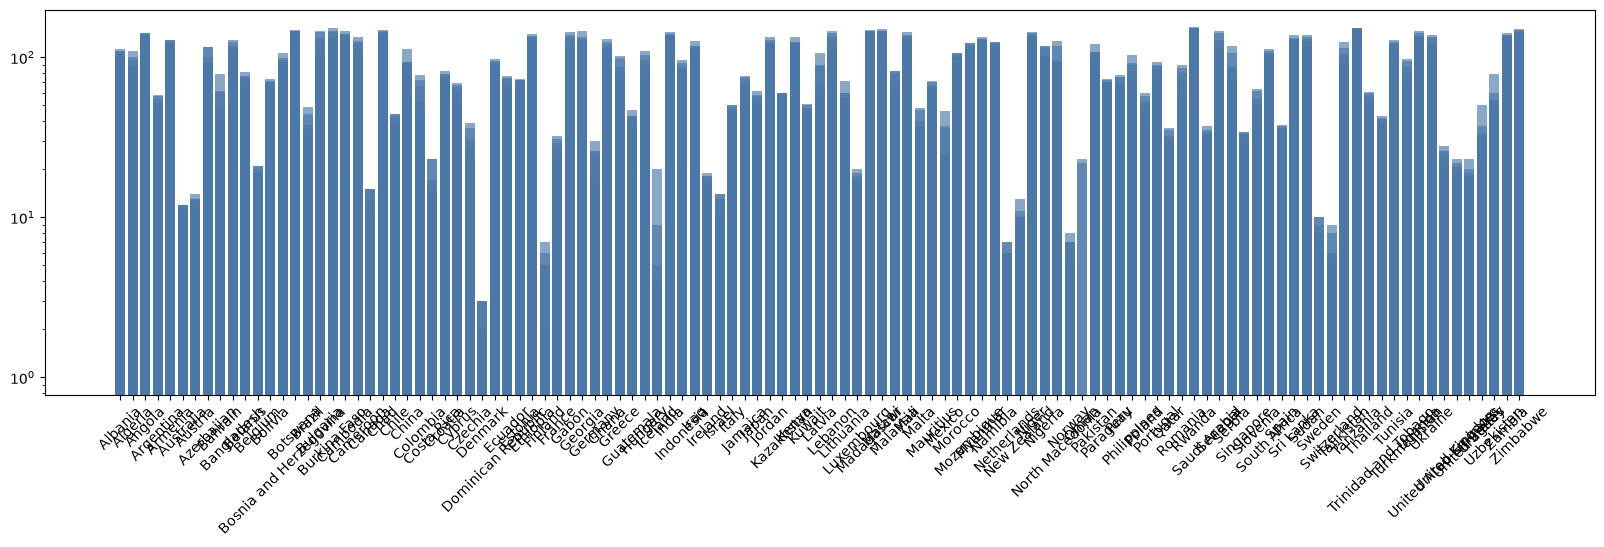

In [ ]:



print("\n")
print("======================================= JUNTAR OS DATASETS ATRAVÉS DOS ANOS =======================================")
print("\n")

combined_datasets = pd.merge(
    happiness_copy,
    working_hours_copy,
    left_on=["Country name", "year"],
    right_on=["Entity", "year"],
    how="inner"
)
combined_datasets = pd.merge(
    combined_datasets,
    gdp_per_capita_copy[["Country Name", "year", "gdp_per_capita"]],
    left_on=["Country name", "year"],
    right_on=["Country Name", "year"],
    how="inner"
)
print(combined_datasets)


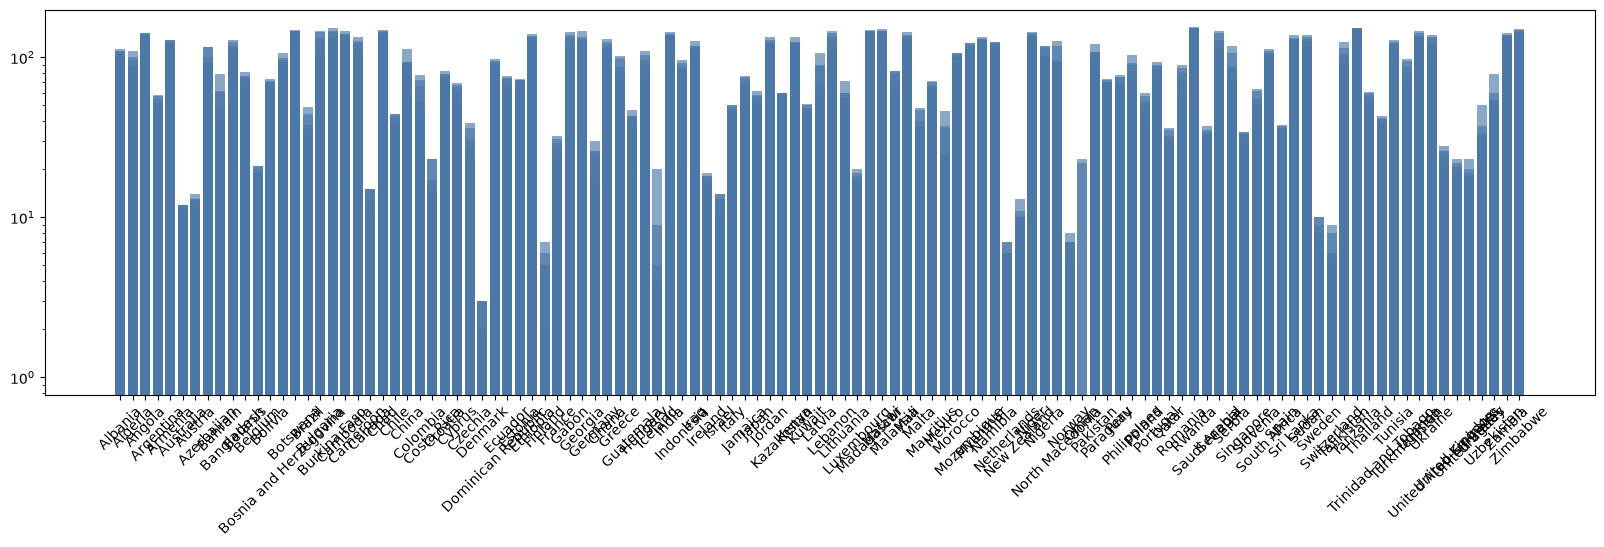

In [70]:
fig, ax = plt.subplots(figsize=(20, 5))
ax.bar(combined_datasets["Country name"], combined_datasets["Rank"], alpha=0.65, color="#4c78a8")
plt.yscale('log')
plt.xticks(rotation=45)
plt.show()

     Country name  Rank  year
399       Finland     1  2023
339       Denmark     2  2023
506       Iceland     3  2023
1113       Sweden     4  2023
566        Israel     5  2023
838   Netherlands     6  2023
897        Norway     7  2023
697    Luxembourg     8  2023
1125  Switzerland     9  2023
54      Australia    10  2023


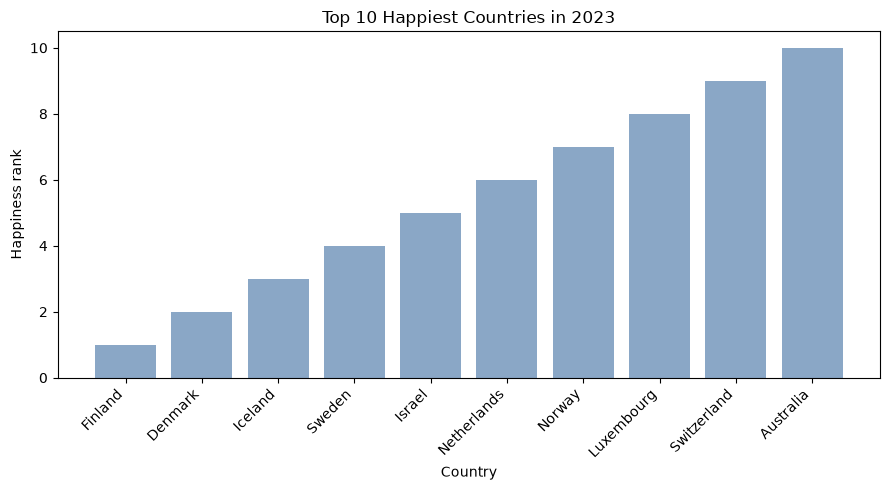

In [ ]:
# Select the latest year in the dataset
latest_year = combined_datasets["year"].max()

top10 = (
    combined_datasets[
        combined_datasets["year"] == latest_year
    ]
    .sort_values("Rank", ascending=True)
    .head(10)
)

print(top10[["Country name", "Rank", "year"]])

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    top10["Country name"],
    top10["Rank"],
    color="#4c78a8",
    alpha=0.65
)

ax.set_title(f"Top 10 Happiest Countries in {latest_year}")
ax.set_xlabel("Country")
ax.set_ylabel("Happiness rank")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

     Country name  Rank  year
673       Lebanon   142  2023
1299     Zimbabwe   138  2023
159      Botswana   137  2023
721        Malawi   136  2023
1287       Zambia   134  2023
1149     Tanzania   131  2023
387      Ethiopia   130  2023
101    Bangladesh   129  2023
1095    Sri Lanka   128  2023
518         India   126  2023


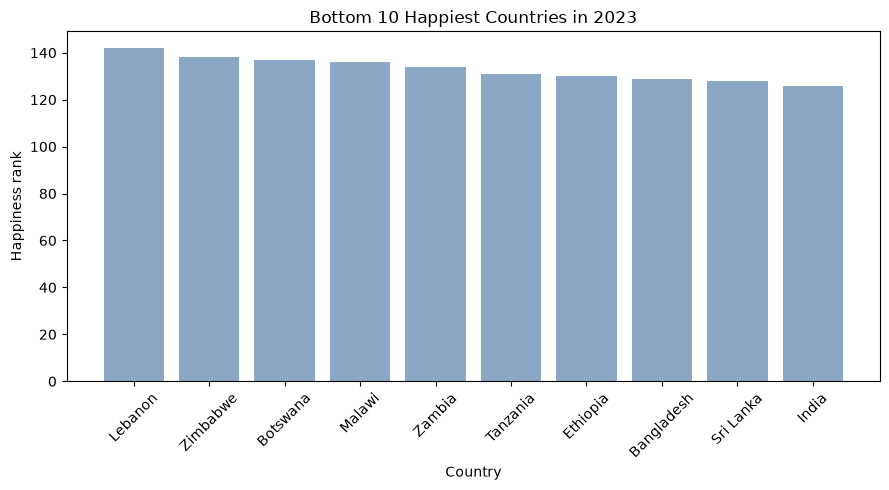

In [72]:
# Select the latest year in the dataset
latest_year = combined_datasets["year"].max()

top10 = (
    combined_datasets[
        combined_datasets["year"] == latest_year
    ]
    .sort_values("Rank", ascending=False)
    .head(10)
)

print(top10[["Country name", "Rank", "year"]])

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    top10["Country name"],
    top10["Rank"],
    color="#4c78a8",
    alpha=0.65
)

ax.set_title(f"Bottom 10 Happiest Countries in {latest_year}")
ax.set_xlabel("Country")
ax.set_ylabel("Happiness rank")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()